# EMQA_L4_price_changes

**Daily price changes before and after 2021**

Energy Markets Quantitative Analysis (EMQA), Lecture 4 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L4/EMQA_L4_price_changes/EMQA_L4_price_changes.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

In [2]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter, NullFormatter

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5,
    'legend.frameon': False, 'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}   # fixed colour per zone / series


def legend_bottom(fig, ncol=4):
    # one legend for the whole figure, centred under the axes
    handles, labels = [], []
    for ax in fig.axes:
        for h, l in zip(*ax.get_legend_handles_labels()):
            if l not in labels:
                handles.append(h)
                labels.append(l)
    fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, 0.0),
               frameon=False, handlelength=2.0, columnspacing=1.2)


def show(key, value):
    # prints a number shown on the slide, under its key in lectures/L4/L4_numbers.json
    print(f'{key:<28} = {value}')


def d(ts):
    return pd.Timestamp(ts).strftime('%Y-%m-%d')

In [3]:
# daily day-ahead base prices (mean of all market time units of the CET/CEST delivery day), EUR/MWh
PD = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', parse_dates=['date_cet']).set_index('date_cet')
START = pd.Timestamp('2015-01-01')
END = pd.Timestamp('2026-10-31')           # cut-off of Lecture 4: last complete month of the download
CAL = pd.date_range(START, END, freq='D')
P = PD[['RO']].reindex(CAL)           # full calendar: missing days stay missing
X = P.diff()                           # daily change X_t = P_t - P_{t-1}; a change next to a gap is missing
print('daily prices', d(START), 'to', d(END), '| missing days in Romania:', int(P['RO'].isna().sum()))

daily prices 2015-01-01 to 2026-10-31 | missing days in Romania: 5


## The risk factor

Prices can be negative, so the lecture uses daily changes $X_t=P_t-P_{t-1}$ (EUR/MWh), not log returns. A buyer of a flat block budgeted at yesterday's price loses $X_t$ per MWh.

In [4]:
x = X['RO'].dropna()
show('dist.RO.max', round(x.max(), 2))
show('dist.RO.max_date', d(x.idxmax()))
show('dist.RO.min', round(x.min(), 2))
show('dist.RO.min_date', d(x.idxmin()))

dist.RO.max                  = 260.77
dist.RO.max_date             = 2022-07-11
dist.RO.min                  = -166.59
dist.RO.min_date             = 2021-12-24


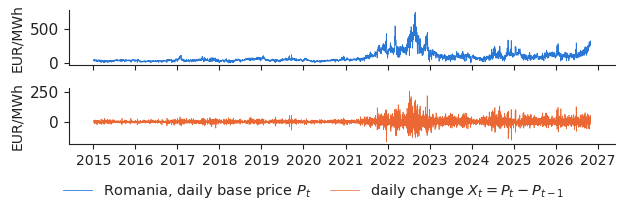

In [5]:
fig, axs = plt.subplots(2, 1, figsize=(6.4, 2.2), sharex=True)
axs[0].plot(P.index, P['RO'], color=PAL['RO'], lw=0.6, label='Romania, daily base price $P_t$')
axs[0].set_ylabel('EUR/MWh', fontsize=10)
axs[1].plot(X.index, X['RO'], color=PAL['DE_LU'], lw=0.5, label='daily change $X_t = P_t - P_{t-1}$')
axs[1].set_ylabel('EUR/MWh', fontsize=10)
axs[1].xaxis.set_major_locator(mdates.YearLocator())
axs[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
axs[1].tick_params(axis='x', labelsize=10)
legend_bottom(fig, ncol=2)
fig.canvas.draw()
legend_top = max(lg.get_window_extent().y1 for lg in fig.legends) / fig.dpi
fig.tight_layout(rect=(0, max(legend_top - 0.08, 0.05) / fig.get_figheight(), 1, 1))
plt.savefig('price_changes.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()